Purpose of Uneven Illumination Correction:
- Standardize image brightness: Reduce lighting differences between the center and edges of images.
- Improve boundary detection: Help the model distinguish actual organoid boundaries from illumination artifacts.
- Improve model training: Encourage the segmentation model to learn organoid shapes and structural features rather than brightness variations.
- Improve generalization: Potentially make segmentation more consistent across different image locations and lighting conditions.

In [1]:
pip install opencv-python numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [31]:
img = cv2.imread(
    r"C:\OneDrive_local_\Desktop\realtime-organoid-XYZ\High_quality_image_23&24\High_quality_image_2024\test21.jpg"
)
if img is None:
    raise FileNotFoundError("image_loading_failed")

(3040, 4056, 3)


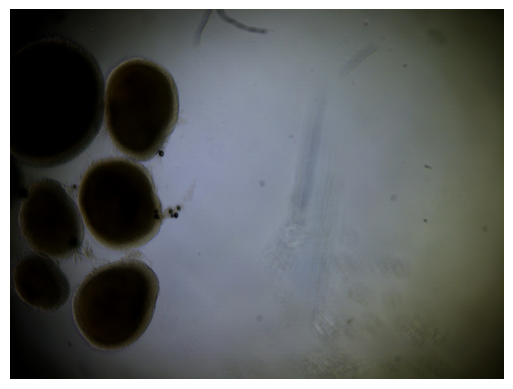

In [32]:
print(img.shape) 
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [33]:
# Convert the BGR image to grayscale
# then to float32 for the illumination correction calculations.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
gray

array([[ 0.,  0.,  0., ..., 14., 14., 15.],
       [ 0.,  0.,  0., ..., 13., 14., 15.],
       [ 0.,  0.,  0., ..., 13., 14., 15.],
       ...,
       [ 0.,  0.,  0., ..., 12., 13., 14.],
       [ 0.,  0.,  0., ..., 11., 13., 15.],
       [ 0.,  0.,  0., ..., 11., 13., 15.]],
      shape=(3040, 4056), dtype=float32)

In [40]:
# Blur the grayscale image to estimate the smooth,
# uneven illumination in the background.
background = cv2.GaussianBlur(gray, (0, 0), sigmaX=120)
background

array([[ 0.14847362,  0.14849366,  0.14855377, ..., 22.847609  ,
        22.84702   , 22.846806  ],
       [ 0.14848606,  0.14850596,  0.14856604, ..., 22.847818  ,
        22.84721   , 22.847     ],
       [ 0.14852305,  0.14854309,  0.14860325, ..., 22.848425  ,
        22.847836  , 22.847624  ],
       ...,
       [ 1.2157875 ,  1.2158787 ,  1.2161503 , ..., 20.025034  ,
        20.0244    , 20.024208  ],
       [ 1.2156286 ,  1.2157195 ,  1.2159908 , ..., 20.02451   ,
        20.023888  , 20.023678  ],
       [ 1.2155776 ,  1.2156678 ,  1.2159382 , ..., 20.024334  ,
        20.023708  , 20.023506  ]], shape=(3040, 4056), dtype=float32)

In [41]:
# Correct uneven illumination by dividing each pixel by the estimated background.
# The minimum value of 1.0 prevents division by zero.
corrected = gray / np.maximum(background, 1.0)

# Find the 1st and 99th percentiles to set the display range
# while ignoring a small number of extreme pixel values.
low, high = np.percentile(corrected, (1, 99))

# Scale values into the range [0, 1] and clip values outside it.
corrected = np.clip(
    (corrected - low) / max(high - low, 1e-6), 0, 1
)

# Convert the result to an 8-bit image with pixel values from 0 to 255.
corrected = (corrected * 255).astype(np.uint8)

# Save the corrected image.
cv2.imwrite("corrected.png", corrected)

# Place the original grayscale image on the left and the corrected image on the right.
comparison = np.hstack([gray.astype(np.uint8), corrected])
cv2.imwrite("comparison.png", comparison)

True

In [42]:
saved = cv2.imwrite("corrected.png", corrected)
print(saved)  # True = saved successfully; False = saving failed

True
